# Lab Results with Reference Ranges

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

Small multiples show one patient's laboratory tests over time. Each test has its normal reference range as a shaded band, and out-of-range results carry an H or L label. Every test keeps its own units and scale, and abnormal values and trends are obvious without reading a table.

## When to use

- Review a patient's lab trends at a glance (rounds, case review, patient portals)
- Show which results are outside the reference range and whether they are improving
- Monitor any set of measurements that have acceptable ranges (process control limits, risk limits)

## Avoid when

- Comparing the same test across many patients (use a funnel plot, box plots or a lasagna plot)
- Reference ranges depend on age, sex or lab and are not known (do not shade a misleading band)
- Exact values and timestamps are required (use the table)

## Alternatives

- Patient timeline
- Table with H/L flags
- Run chart (one measure, with the median and run rules)

## Design tips

- Give every test its own y-axis and units; never force different tests onto one scale
- Flag out-of-range values with a text label (H/L), not color alone
- Keep the time axis shared so changes across tests line up
- Use de-identified data (shift dates, drop identifiers); executed notebooks store their outputs

## Example

Five simulated lab tests for one patient with chronic kidney disease, measured over 12 months, with adult reference ranges.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from vizlib.health import reference_flags
import matplotlib.dates as mdates

### Data

In [2]:
rng = np.random.default_rng(410)
dates = pd.date_range("2024-01-15", periods=13, freq="28D")
m = np.arange(len(dates))
after = 1 / (1 + np.exp(-(m - 5) * 1.5))            # effect of a medication change around month 5
labs = {  # test: (units, low, high, values)
    "Creatinine": ("mg/dL", 0.6, 1.3, 1.9 - 0.65 * after + rng.normal(0, 0.06, m.size)),
    "Potassium": ("mmol/L", 3.5, 5.1, 5.7 - 0.9 * after + rng.normal(0, 0.12, m.size)),
    "Haemoglobin": ("g/dL", 12.0, 16.0, 10.6 + 0.6 * after + rng.normal(0, 0.25, m.size)),
    "Sodium": ("mmol/L", 135, 145, 140 + rng.normal(0, 1.0, m.size)),
    "Glucose (fasting)": ("mg/dL", 70, 100, 86 + rng.normal(0, 2.5, m.size) + 30 * (m == 8)),
}
records = pd.DataFrame([
    dict(test=t, units=u, low=lo, high=hi, date=d, value=round(float(v), 2))
    for t, (u, lo, hi, vals) in labs.items() for d, v in zip(dates, vals)])
records["flag"] = np.concatenate([reference_flags(g["value"], g["low"].iloc[0], g["high"].iloc[0])
                                  for _, g in records.groupby("test", sort=False)])
records[records["flag"] != ""].head()

,test,units,low,high,date,value,flag
0,Creatinine,mg/dL,0.6,1.3,2024-01-15,1.88,H
1,Creatinine,mg/dL,0.6,1.3,2024-02-12,1.89,H
2,Creatinine,mg/dL,0.6,1.3,2024-03-11,1.94,H
3,Creatinine,mg/dL,0.6,1.3,2024-04-08,1.78,H
4,Creatinine,mg/dL,0.6,1.3,2024-05-06,1.82,H


### Plot

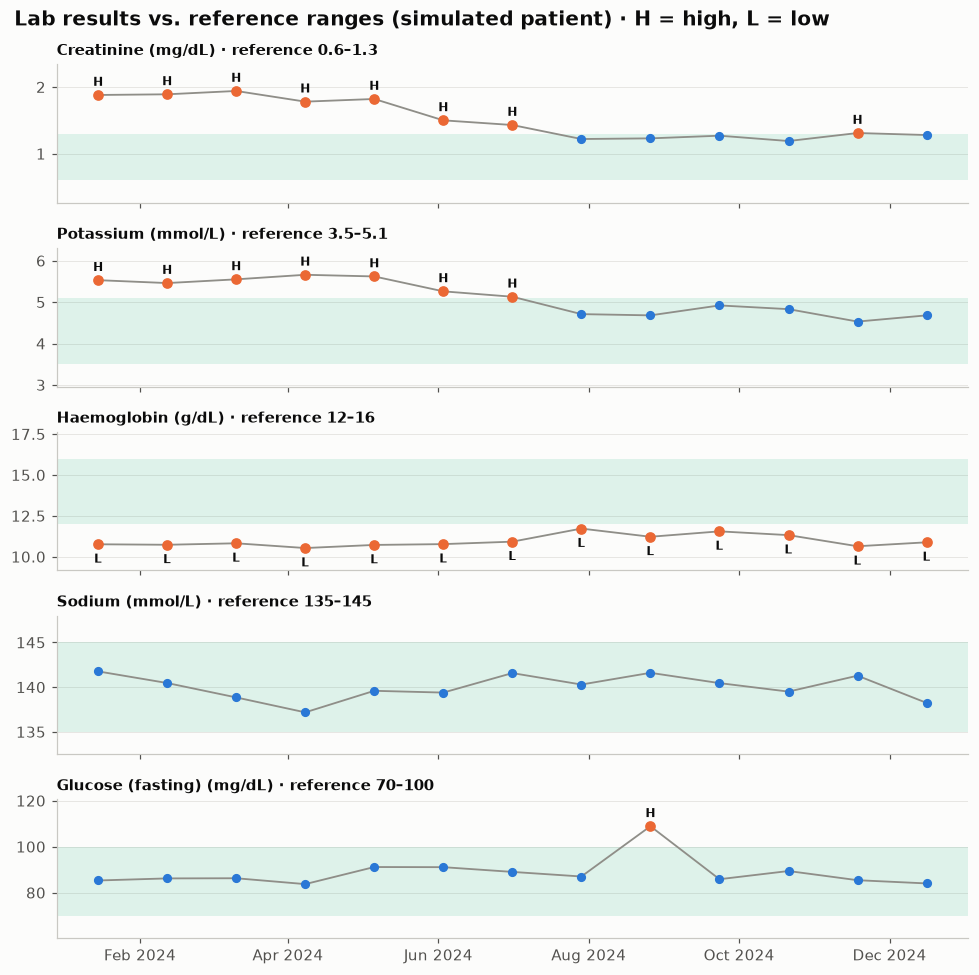

In [3]:
tests = list(labs)
fig, axes = plt.subplots(len(tests), 1, figsize=(9, 9), sharex=True)
for ax, test in zip(axes, tests):
    g = records[records["test"] == test]
    lo, hi, units = g["low"].iloc[0], g["high"].iloc[0], g["units"].iloc[0]
    ax.axhspan(lo, hi, color=PALETTE[2], alpha=0.13, linewidth=0)
    ax.plot(g["date"], g["value"], "-", color="#8f8e88", linewidth=1.2)
    normal, out = g[g["flag"] == ""], g[g["flag"] != ""]
    ax.plot(normal["date"], normal["value"], "o", color=PALETTE[0], markersize=5)
    ax.plot(out["date"], out["value"], "o", color=PALETTE[1], markersize=6)
    for _, r in out.iterrows():
        ax.annotate(r["flag"], (r["date"], r["value"]), xytext=(0, 6 if r["flag"] == "H" else -12),
                    textcoords="offset points", ha="center", fontsize=8, fontweight="bold", color="#0b0b0b")
    span = max(g["value"].max(), hi) - min(g["value"].min(), lo)
    ax.set_ylim(min(g["value"].min(), lo) - 0.25 * span, max(g["value"].max(), hi) + 0.3 * span)
    ax.set_title(f"{test} ({units}) · reference {lo:g}–{hi:g}", fontsize=10, loc="left")
    ax.grid(axis="x", visible=False)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Lab results vs. reference ranges (simulated patient) · H = high, L = low",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Creatinine and potassium start high (H), above their bands, fall after the medication change around month 5 and are back in range from August (creatinine is borderline high once more in November). Haemoglobin stays low (L) throughout. Sodium and glucose stay within range except for one high glucose.

---
Standalone script: [`lab_reference_ranges.py`](lab_reference_ranges.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)